# Training Agents with RL: From Tool Calls to Real Agent Programs

*Extend the training loop from the previous articles to agents that call tools over several turns, then to an existing agent program that we can't rewrite, and see how a production setup trains it, using verl and Agent Lightning as our example.*

## Motivation

In the previous two articles, every sample was a single response to a single prompt: the model wrote an answer, and we scored it. However, more and more of what RL is used for today is training **agents**: models that call tools, read the results, and carry on over many turns, until they decide that they're done. Often, the agent is also an existing program, built with an agent framework, with its own tools, its own prompts and its own way of talking to the model.

This changes the part of the training step that we haven't questioned so far: where the samples come from. The rest of the training step (π_old, the advantages, the clipped loss and the update) stays the same, but producing a sample, and turning it into training data, becomes much harder to get right.

As before, we'll build each part ourselves before swapping in a real framework's version. For agents, our example is [Agent Lightning](https://github.com/microsoft/agent-lightning), which trains existing agent programs, using verl for everything else.

## What this article covers

1. What changes when the model calls tools over several turns? (§1)
2. Why can't we train an existing agent program from its logs? (§2)
3. How do we record exactly what an agent's model produced, and turn it into training data? (§3)
4. What does a production framework for training agents add? (§4)
5. Where does an agent's reward come from, and where would an LLM judge fit in? (§5)
6. What does a full training run of a real agent look like? (§6)

**What we need to know already.** The previous two articles: the training step and its batch (the first article, §1.7–§2), and the inference engine, weight sync and `DataProto` (the second article, §1, §2 and §4). Their code is imported here from `tutorial/lib/`.

**Hardware and time.** One GPU with about 80 GB, and about 6 minutes on an H100. From §3 onwards, we use Qwen2.5-1.5B-Instruct, a 3 GB download.

## 0. Setup

The functions from the previous articles are imported from `tutorial/lib/`, where they are copied verbatim.

In [1]:
import gc
import json
import os
import random
import re
import shutil
import subprocess
import sys
import threading
import time
import uuid
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples" / "calc_x").is_dir())
sys.path.insert(0, str(REPO / "tutorial/lib"))  # shared code: paths, the model names, the seed
from common import (CALC_X_DATA, CALC_X_MODEL, MODEL, SEED, SERVICES, SHM, VENV_BIN, WORK, follow_log,  # noqa: E402
                    gpu_free_gib, log_tail, setup, start_service, stop_service, wait_until_healthy)

setup()  # creates the working folders, seeds the random number generators, checks the GPU is free

import httpx  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from verl import DataProto  # noqa: E402
from vllm import LLM  # noqa: E402

from arith_task import make_problems, reward_fn, safe_eval  # noqa: E402
from rl_core import (LR, PAD_ID, STOP_IDS, compute_log_probs, grpo_advantages, load_policy, make_optimizer,  # noqa: E402
                     make_padded_batch, plot_histories, ppo_update, print_step_metrics, push_weights, save_for_inference,
                     tokenizer, verl_ppo_loss, vllm_generate)
from verl_core import add_advantages, compute_batch_metrics  # noqa: E402

repo: /home/azureuser/localfiles/agl-rl-tutorials
python: /home/azureuser/localfiles/agl-rl-tutorials/.venv/bin/python
GPU: NVIDIA H100 NVL, 93 of 93 GiB free


WARNING 11-16 15:34:35 [config.py:70] Support for Transformers v4 is deprecated. The Transformers v4 codepath will become unmaintained in vLLM v0.22.0 and will be removed in vLLM v0.24.0. Please upgrade to Transformers v5: pip install --upgrade transformers


## 1. Multi-turn: agents that call tools

So far, a sample has been one prompt and one response. An agent works differently: the model writes a **tool call**, something executes it, the result is added to the context, and the model carries on writing, possibly calling more tools, until it gives its answer. Everything that isn't the model, here the tools, is known as the **environment**.

For training, this means that a single sample becomes one long sequence, in which some tokens come from the model, and some from the environment:

![One multi-turn episode as a single sequence: the prompt, then the model's tool call (response_mask = 1, trained), the tool's response (response_mask = 0, context only), and the model's final answer (response_mask = 1, trained)](images/multi_turn_sequence.png)

**Only the model's tokens are trained.** The tool's output stays in the sequence, as the model's later tokens were written *after reading it*, so it's part of their context. However, the model didn't choose those tokens, so we mustn't train on them. If we did, the update would push up the log-prob of, say, `232242` inside a tool response, teaching the model to *predict* tool results, which is exactly how a model learns to make them up instead of calling the tool. Setting `response_mask` to 0 for these tokens keeps them as context, but out of the loss.

#### A task that needs a tool

To make a tool worth calling, we need a harder task than before: `abc × def − ghij`, which a 0.5B model can't reliably work out in its head. The tool is a calculator, which uses `safe_eval` from the arithmetic task, and we describe it to the model with a JSON schema, passed to the chat template through its `tools=` argument. Qwen's template adds the description to the system prompt, along with instructions to write each call as `<tool_call>{json}</tool_call>`:

In [2]:
CALC_TOOL = {
    "type": "function",
    "function": {
        "name": "calculate",
        "description": "Evaluate an arithmetic expression with numbers, + - * / and parentheses.",
        "parameters": {
            "type": "object",
            "properties": {"expression": {"type": "string", "description": "The arithmetic expression, e.g. '123 * 456 - 789'."}},
            "required": ["expression"],
        },
    },
}
TOOL_INSTRUCTION = r"Use the calculate tool for the arithmetic, then give the final answer as \boxed{N}."
HARD_TRAIN = make_problems(2000, seed=3, hard=True)


def tool_prompt_ids(question: str) -> list[int]:
    # Like chat_prompt_ids, but the chat template also describes the calculate tool
    messages = [{"role": "user", "content": f"{question} {TOOL_INSTRUCTION}"}]
    return tokenizer.apply_chat_template(messages, tools=[CALC_TOOL], add_generation_prompt=True)


print(tokenizer.decode(tool_prompt_ids(HARD_TRAIN[0]["question"])))

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "calculate", "description": "Evaluate an arithmetic expression with numbers, + - * / and parentheses.", "parameters": {"type": "object", "properties": {"expression": {"type": "string", "description": "The arithmetic expression, e.g. '123 * 456 - 789'."}}, "required": ["expression"]}}}
</tools>

For each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:
<tool_call>
{"name": <function-name>, "arguments": <args-json-object>}
</tool_call><|im_end|>
<|im_start|>user
What is 343 * 706 - 9916? Use the calculate tool for the arithmetic, then give the final answer as \boxed{N}.<|im_end|>
<|im_start|>assistant



#### Running the tool, and formatting its result

When the model writes a tool call, we parse the JSON, run the calculator, and add the result to the sequence. There is one important detail here: **the tool's result must be formatted exactly as the chat template formats it.** When the agent is used for real, through vLLM's chat API, an agent framework or verl's agent loop, tool results are always formatted by the chat template. If our training sequences formatted them even slightly differently, the model would be trained on contexts it never sees in real use.

So, we write the formatting by hand, in `observation_text`, and then **check it against the template**: we render a short conversation that ends with a tool result and the start of a new assistant turn, and check that it ends with exactly our text.

In [3]:
TOOL_CALL = re.compile(r"<tool_call>\s*(.*?)\s*</tool_call>", re.S)


def run_tool_call(tool_call_json: str) -> str:
    # Parse one model-written tool call and execute it. Errors go back to the model as text
    try:
        call = json.loads(tool_call_json)
        arguments = call["arguments"]
        if isinstance(arguments, str):  # some models write the arguments as a JSON string inside the JSON
            arguments = json.loads(arguments)
        if call.get("name") != "calculate":
            return f"Error: unknown tool {call.get('name')!r}"
        value = safe_eval(str(arguments["expression"]))
        if float(value).is_integer():
            return str(int(value))
        return f"{value:.6g}"
    except Exception as exc:
        return f"Error: {exc}"


def observation_text(results: list[str]) -> str:
    # What Qwen's chat template appends after the model's <|im_end|>: the tool results, then a new assistant turn
    text = "\n<|im_start|>user"
    for result in results:
        text += f"\n<tool_response>\n{result}\n</tool_response>"
    text += "<|im_end|>\n<|im_start|>assistant\n"
    return text

In [4]:
template_text = tokenizer.apply_chat_template(
    [
        {"role": "user", "content": "What is 2*3?"},
        {"role": "assistant", "content": "", "tool_calls": [{"type": "function", "function": {"name": "calculate", "arguments": {"expression": "2*3"}}}]},
        {"role": "tool", "content": "6"},
    ],
    tools=[CALC_TOOL], add_generation_prompt=True, tokenize=False,
)
print("our observation text matches the chat template:", template_text.endswith("<|im_end|>" + observation_text(["6"])))
print(repr(observation_text(["6"])))

our observation text matches the chat template: True
'\n<|im_start|>user\n<tool_response>\n6\n</tool_response><|im_end|>\n<|im_start|>assistant\n'


#### The multi-turn loop

Now we can write `run_episodes`, which runs a whole group of attempts, known as **episodes**, turn by turn. Each episode is a dict that grows as it goes: `response_ids` holds everything after the prompt, the model's turns and the tool results, in order, and `mask` records which is which. For example, here is how a typical episode is built up:

| Turn | What happens | Added to `response_ids` | `mask` |
|---|---|---|---|
| 1 | the model writes a tool call, and stops | `<tool_call>{"name": "calculate", ...}</tool_call><\|im_end\|>` | 1 |
| | we parse the call and run the calculator → `232242` | `<\|im_start\|>user <tool_response>232242</tool_response><\|im_end\|><\|im_start\|>assistant` | 0 |
| 2 | the model reads the result and answers | `The result ... is \boxed{232242}.<\|im_end\|>` | 1 |
| | no tool call in this turn, so the episode is done | | |

At each turn, every episode that is still going is sent to vLLM, all together, each continuing from its prompt plus everything so far. An episode ends when the model's turn contains **no tool call** (it has given its answer), when the turn was **cut off** by `max_tokens` (we don't run a half-written tool call), or after `max_turns`. The reward is computed from the model's last turn.

The tokens of the tool results get a log-prob of 0.0, as a placeholder; they are masked out, so it's never used.

In [5]:
def run_episodes(problems, samples_per_prompt: int, max_turns: int = 3, max_tokens: int = 256) -> list[dict]:
    # Multi-turn rollouts: generate, run tool calls, append their results, repeat. All in token space
    episodes = []
    for group, problem in enumerate(problems):
        for _ in range(samples_per_prompt):
            episodes.append({
                "question": problem["question"], "answer": problem["answer"], "group": group,
                "prompt_ids": tool_prompt_ids(problem["question"]),
                "response_ids": [],  # model turns and tool results, in order
                "mask": [],          # 1 for the model's tokens (trained), 0 for tool results (context only)
                "log_probs": [],     # the inference engine's log-probs; 0.0 for tool results
                "tool_calls": 0, "tool_results": [], "done": False,
            })

    for turn in range(max_turns):
        active = [episode for episode in episodes if not episode["done"]]
        if not active:
            break

        # One model turn for every active episode, continuing from everything so far
        contexts = [episode["prompt_ids"] + episode["response_ids"] for episode in active]
        turn_outputs = vllm_generate(llm, contexts, 1, max_tokens)

        for episode, output in zip(active, turn_outputs):
            episode["response_ids"] += output["response_ids"]
            episode["mask"] += [1] * len(output["response_ids"])
            episode["log_probs"] += output["log_probs"]
            episode["last_text"] = tokenizer.decode(output["response_ids"])

            calls = TOOL_CALL.findall(episode["last_text"])
            finished = bool(output["response_ids"]) and output["response_ids"][-1] in STOP_IDS  # stopped, not cut off at max_tokens
            if not calls or not finished or turn == max_turns - 1:
                episode["done"] = True
                continue

            # Run the tool calls, and add their results as environment tokens (mask 0: not trained)
            results = [run_tool_call(call) for call in calls]
            observation_ids = tokenizer.encode(observation_text(results), add_special_tokens=False)
            episode["response_ids"] += observation_ids
            episode["mask"] += [0] * len(observation_ids)
            episode["log_probs"] += [0.0] * len(observation_ids)
            episode["tool_calls"] += len(calls)
            episode["tool_results"].append(results)

    for episode in episodes:
        episode["reward"] = reward_fn(episode["last_text"], episode["answer"])
    return episodes

Let's load the 0.5B policy from the previous articles, with its optimizer and a vLLM engine on the same GPU, and run 4 episodes for each of 4 questions:

In [6]:
policy = load_policy()  # Qwen2.5-0.5B-Instruct, the original weights
optimizer = make_optimizer(policy, LR)
llm = LLM(model=MODEL, gpu_memory_utilization=0.3, max_model_len=4096, seed=SEED)

episodes = run_episodes(HARD_TRAIN[:4], samples_per_prompt=4)
for episode in episodes[:2]:
    print("═" * 100, f"\nreward {episode['reward']} | tool calls {episode['tool_calls']} | answer {episode['answer']}")
    print(tokenizer.decode(episode["response_ids"]))

WARNING 11-16 15:34:41 [system_utils.py:157] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshooting.html#python-multiprocessing for more information. Reasons: CUDA is initialized


WARNING 11-16 15:34:44 [config.py:70] Support for Transformers v4 is deprecated. The Transformers v4 codepath will become unmaintained in vLLM v0.22.0 and will be removed in vLLM v0.24.0. Please upgrade to Transformers v5: pip install --upgrade transformers


(EngineCore pid=267291) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore pid=267291) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  8.02it/s]
(EngineCore pid=267291) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  8.01it/s]
(EngineCore pid=267291) 


(EngineCore pid=267291) 2026-11-16 15:34:53,482 - INFO - autotuner.py:615 - flashinfer.jit: [Autotuner]: Autotuning process starts ...
(EngineCore pid=267291) 2026-11-16 15:34:53,489 - INFO - autotuner.py:634 - flashinfer.jit: [Autotuner]: Autotuning process ends


(EngineCore pid=267291) 
Capturing CUDA graphs (mixed prefill-decode, PIECEWISE):   0%|          | 0/51 [00:00<?, ?it/s]
Capturing CUDA graphs (mixed prefill-decode, PIECEWISE):  12%|█▏        | 6/51 [00:00<00:00, 52.94it/s]


Capturing CUDA graphs (mixed prefill-decode, PIECEWISE):  24%|██▎       | 12/51 [00:00<00:00, 51.21it/s]
Capturing CUDA graphs (mixed prefill-decode, PIECEWISE):  35%|███▌      | 18/51 [00:00<00:00, 51.25it/s]

... (5 outputs left out)


Capturing CUDA graphs (decode, FULL):  82%|████████▏ | 42/51 [00:00<00:00, 68.39it/s]


Capturing CUDA graphs (decode, FULL): 100%|██████████| 51/51 [00:00<00:00, 68.52it/s]


(EngineCore pid=267291) WARNING 11-16 15:34:57 [jit_monitor.py:103] Triton kernel JIT compilation during inference: _compute_slot_mapping_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.


════════════════════════════════════════════════════════════════════════════════════════════════════ 
reward 0.0 | tool calls 1 | answer 232242
<tool_call>
{"name": "calculate", "arguments": {"expression": "343 * 706 - 9916"}}
</tool_call><|im_end|>
<|im_start|>user
<tool_response>
232242
</tool_response><|im_end|>
<|im_start|>assistant
The result of the arithmetic expression 343 * 706 - 9916 is 232242.<|im_end|>
════════════════════════════════════════════════════════════════════════════════════════════════════ 
reward 0.0 | tool calls 1 | answer 232242
<tool_call>
{"name": "calculate", "arguments": {"expression": "343 * 706 - 9916"}}
</tool_call><|im_end|>
<|im_start|>user
<tool_response>
232242
</tool_response><|im_end|>
<|im_start|>assistant
The arithmetic expression 343 * 706 - 9916 evaluates to 232,242.<|im_end|>


Both episodes did exactly what we hoped for with the tool: the model wrote a correct tool call, got the right number back, and then wrote its final answer. However, both score 0, as neither put the answer in `\boxed{}`; the second even wrote it as `232,242`. So, with the arithmetic done by the tool, the format is almost the only thing left for the model to learn.

To see the mask, let's colour an episode's response by it: green tokens are trained, and orange ones are context only.

In [7]:
import html

from IPython.display import HTML, display


def show_episode(episode: dict) -> None:
    # Green: the model's tokens (trained). Orange: the environment's tokens (context only)
    # Group consecutive tokens with the same mask value into spans of (mask value, token ids)
    spans = []
    for token_id, trained in zip(episode["response_ids"], episode["mask"]):
        if spans and spans[-1][0] == trained:
            spans[-1][1].append(token_id)
        else:
            spans.append((trained, [token_id]))
    style = {1: "background:#b9f0b4;color:#000", 0: "background:#ffd59e;color:#000"}
    body = ""
    for trained, token_ids in spans:
        text = html.escape(tokenizer.decode(token_ids)).replace("\n", "↵<br>")
        body += f'<span style="{style[trained]}">{text}</span>'
    display(HTML(f"<b>reward {episode['reward']}, {sum(episode['mask'])} trained of {len(episode['mask'])} response tokens</b>"
                 f'<div style="font-family:monospace;font-size:12px;border:1px solid #ccc;padding:6px">{body}</div>'))


# An episode that used the tool and got the answer right, if there is one
show_episode(max(episodes, key=lambda episode: (episode["tool_calls"] > 0, episode["reward"])))

#### Training on episodes

Training on these episodes needs **no change to the update**. The batch has the same keys as before, and `response_mask`, the green and orange colouring above, already removes the tool results from the loss. This is why verl's training code doesn't know or care whether a row came from one turn or ten: everything that is specific to multi-turn lives in how the rollout builds the sequence and its mask.

`episodes_to_batch` builds a `DataProto` from the episodes, using `make_padded_batch`'s optional third argument for the mask. As in the previous article, each episode's reward goes on its last token, and vLLM's log-probs are kept as `rollout_log_probs`, for `logp_mismatch`. The training step is then the previous article's, with `run_episodes` in place of `vllm_generate`, and one extra metric: `tool use`, the fraction of episodes that called the tool at least once.

In [ ]:
def episodes_to_batch(episodes: list[dict]) -> DataProto:
    batch = DataProto.from_dict(
        tensors=make_padded_batch(
            [episode["prompt_ids"] for episode in episodes],
            [episode["response_ids"] for episode in episodes],
            [episode["mask"] for episode in episodes],
        ),
        non_tensors={"uid": np.array([episode["group"] for episode in episodes], dtype=object)},
    )
    
    response_width = batch.batch["responses"].shape[1]
    token_level_rewards = torch.zeros(len(episodes), response_width)
    rollout_log_probs = torch.zeros(len(episodes), response_width)
    
    for row, episode in enumerate(episodes):
        token_level_rewards[row, max(len(episode["response_ids"]), 1) - 1] = episode["reward"]  # the reward on the last token
        rollout_log_probs[row, : len(episode["log_probs"])] = torch.tensor(episode["log_probs"])
    
    batch.batch["token_level_rewards"] = token_level_rewards
    batch.batch["rollout_log_probs"] = rollout_log_probs
    return batch


def tool_rl_step(problems, samples_per_prompt: int = 8) -> tuple[dict, DataProto, list[dict]]:
    timing = {}

    # 1. Sample: multi-turn episodes
    start = time.time()
    episodes = run_episodes(problems, samples_per_prompt)
    timing["gen"] = time.time() - start

    # 2-3. Rewards (already in the episodes), π_old and advantages
    batch = episodes_to_batch(episodes)
    batch.batch["old_log_probs"] = compute_log_probs(policy, batch.batch)
    add_advantages(batch)

    # 4. Update, exactly as before
    start = time.time()
    stats = ppo_update(
        policy, optimizer, batch.batch,
        old_log_probs=batch.batch["old_log_probs"], advantages=batch.batch["advantages"], loss_fn=verl_ppo_loss,
    )
    timing["update"] = time.time() - start

    start = time.time()
    push_weights(policy, llm)
    timing["sync"] = time.time() - start

    tool_use = float(np.mean([episode["tool_calls"] > 0 for episode in episodes]))  # the fraction of episodes that called the tool
    metrics = {**compute_batch_metrics(batch), **stats, "tool_use": tool_use}
    metrics.update({f"time/{name}": seconds for name, seconds in timing.items()})
    return metrics, batch, episodes

Let's train for 6 steps of 16 questions × 8 episodes:

In [9]:
question_rng = random.Random(SEED)
tool_history, all_episodes = [], []

for step in range(6):
    metrics, _, step_episodes = tool_rl_step(question_rng.sample(HARD_TRAIN, 16))
    tool_history.append(metrics)
    all_episodes += step_episodes
    print_step_metrics(step, metrics)
    print(f"        tool use {metrics['tool_use']:.2f}")

(EngineCore pid=267291) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore pid=267291) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.24it/s]
(EngineCore pid=267291) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.24it/s]
(EngineCore pid=267291) 


(EngineCore pid=267291) WARNING 11-16 15:35:02 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step  0 | reward 0.117 | len  62.7 | grad_norm 4.064 | logp mismatch 0.0033 | gen  0.5s update  2.4s sync  1.3s
        tool use 0.98


(EngineCore pid=267291) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore pid=267291) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.28it/s]
(EngineCore pid=267291) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.28it/s]
(EngineCore pid=267291) 


(EngineCore pid=267291) WARNING 11-16 15:35:06 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step  1 | reward 0.375 | len  65.1 | grad_norm 5.591 | logp mismatch 0.0047 | gen  0.6s update  2.2s sync  1.4s
        tool use 0.98


(EngineCore pid=267291) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore pid=267291) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.25it/s]
(EngineCore pid=267291) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.24it/s]
(EngineCore pid=267291) 


(EngineCore pid=267291) WARNING 11-16 15:35:11 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step  2 | reward 0.875 | len  66.2 | grad_norm 3.228 | logp mismatch 0.0038 | gen  0.7s update  2.2s sync  1.4s
        tool use 0.98


... (2 outputs left out)

(EngineCore pid=267291) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore pid=267291) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.25it/s]
(EngineCore pid=267291) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.25it/s]
(EngineCore pid=267291) 


(EngineCore pid=267291) WARNING 11-16 15:35:20 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step  4 | reward 0.984 | len  65.0 | grad_norm 1.160 | logp mismatch 0.0037 | gen  0.4s update  2.4s sync  1.4s
        tool use 0.99


(EngineCore pid=267291) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore pid=267291) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.27it/s]
(EngineCore pid=267291) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.27it/s]
(EngineCore pid=267291) 


(EngineCore pid=267291) WARNING 11-16 15:35:25 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step  5 | reward 0.977 | len  68.4 | grad_norm 2.579 | logp mismatch 0.0055 | gen  0.8s update  2.3s sync  1.4s
        tool use 0.98


The model calls the tool in almost every episode from the start (`tool use` is 0.98 or more), and the reward jumps from 0.12 to 0.98 within 4 steps. As in the previous article (§2), this jump is the format: the model learns to put the number that the tool gave it in `\boxed{}`. The update itself is no different from before; only the sequences it trains on have changed.

#### The same thing in verl: `ToolAgentLoop`

verl ships this loop as `ToolAgentLoop`: a small state machine that works directly on token IDs, generating, parsing tool calls, running tools and appending their results with `response_mask = 0`, just as `run_episodes` does:

| `run_episodes` | verl's `ToolAgentLoop` |
|---|---|
| `tool_prompt_ids` (the chat template, with `tools=`) | applies the chat template with the tools' schemas |
| `vllm_generate(llm, prompt_ids + response_ids, 1)` | asks its vLLM server to continue from the token IDs so far |
| `mask += [1] * len(response)` | `response_mask += [1] * len(response_ids)` |
| `TOOL_CALL.findall` and `run_tool_call` | a tool-call parser (`hermes` for Qwen), then the tool itself |
| `observation_text`, tokenized, with mask 0 | the tool results, formatted by the chat template, with mask 0 |
| `max_turns` | `multi_turn.max_assistant_turns` |
| the calculator | a Python function decorated with `@function_tool`, or a `BaseTool` subclass |

To use it, we would write the agent **in verl's terms**: its tools as verl tools, the conversation as a verl dataset row, and its limits as verl config. For an agent that we design for RL training from the start, that's a good deal. However, many agents already exist.

## 2. An existing agent

Let's take an agent that already exists: the Calc-X agent, which comes with Agent Lightning (`examples/calc_x/calc_agent.py`). It answers maths word problems from the [Calc-X](https://huggingface.co/datasets/MU-NLPC/Calc-X) dataset, with a calculator tool, and it's ordinary application code, built with the AutoGen agent framework:

In [10]:
print((REPO / "examples/calc_x/calc_agent.py").read_text())

# Copyright (c) Microsoft. All rights reserved.

"""Minimal Calc-X agent entrypoint."""

# AutoGen is an optional runtime dependency for this example container.
# pyright: reportMissingImports=false

from __future__ import annotations

import asyncio
import os
import re

import httpx
from eval_utils import scalar_are_results_same


class Agent:
    async def run(self) -> None:
        from autogen_agentchat.agents import AssistantAgent
        from autogen_core.models import ModelFamily
        from autogen_ext.models.openai import OpenAIChatCompletionClient
        from autogen_ext.tools.mcp import McpWorkbench, StdioServerParams

        question = os.environ["QUESTION"]
        result = os.environ["RESULT"]
        agl_key = os.environ["AGL_KEY"]
        event_url = os.environ["AGL_EVENT_URL"]
        openai_base_url = os.environ["AGL_OPENAI_BASE_URL"]

        calculator_mcp_server = StdioServerParams(
            command="python",
            args=["-m", "mcp_server_calculator"],


If we tried to put this agent inside `run_episodes`, every one of its assumptions would break:

* **It speaks HTTP, not tokens.** It calls an OpenAI-compatible `/chat/completions` endpoint, and gets back text and parsed `tool_calls`. There is no `generate(prompt_ids)` to call.
* **It owns the control flow.** AutoGen decides when to call the model, how to format the tool results, and when to stop. With `reflect_on_tool_use=True`, its last call even uses a different system prompt, without the tools.
* **Its tools run in separate processes.** The calculator is an MCP server, which the agent starts itself. Other agents run code in containers, browse the web, or call internal services.
* **It computes its own reward**, and reports it at the end.

We could rewrite it as a verl agent loop, but then we'd be training *the rewrite*, and every future change to the real agent would have to be copied over. The alternative is to leave the agent alone, and record what it does. But where from? Its logs contain **text**, whereas training needs **token IDs and log-probs**. Turning logged text back into tokens *usually* works, and that's exactly the problem: when it doesn't, nothing tells us.

#### Why text → tokens isn't reliable

The same text can be split into tokens in more than one way. The tokenizer always produces one particular split, known as the *canonical* one, but at temperature 1, the model can sample a different one:

In [11]:
canonical = tokenizer.encode(" calculation", add_special_tokens=False)  # what the tokenizer produces
sampled = tokenizer.encode(" calc", add_special_tokens=False) + tokenizer.encode("ulation", add_special_tokens=False)  # a split the model could sample

print("canonical:", canonical, [tokenizer.decode([token]) for token in canonical])
print("sampled:  ", sampled, [tokenizer.decode([token]) for token in sampled])
print("both decode to the same text:", tokenizer.decode(canonical) == tokenizer.decode(sampled))
print("re-encoding the sampled text gives:", tokenizer.encode(tokenizer.decode(sampled), add_special_tokens=False))

canonical: [21937] [' calculation']
sampled:   [10035, 2914] [' calc', 'ulation']
both decode to the same text: True
re-encoding the sampled text gives: [21937]


If the model sampled ` calc` followed by `ulation`, a log of the text says " calculation", and re-encoding it gives a single token, which the model never produced. Training on it would push up a token the model didn't choose, with a log-prob that doesn't belong to it.

We can measure how often this happens on the episodes from §1, where we *do* know the true tokens. Let's run two checks:

1. **Text round-trip:** decode each of the model's turns to text, and encode it again, which catches exactly the problem above.
2. **Re-rendering from a chat log:** rebuild each episode as a list of chat messages, with parsed `tool_calls`, which is what an HTTP log of the agent would contain. Then, apply the chat template, and compare the result with the real token sequence. The template writes the tool-call JSON its own way, and can format whitespace differently from what the model wrote.

In [12]:
def split_model_turns(episode: dict) -> list[list[int]]:
    # Split an episode's response into the model's turns, dropping the tool results between them
    turns, current = [], []
    for token_id, trained in zip(episode["response_ids"], episode["mask"]):
        if trained:
            current.append(token_id)
        elif current:  # a tool result starts: the model's turn is over
            turns.append(current)
            current = []
    if current:
        turns.append(current)
    return turns


def rerender_from_messages(episode: dict) -> list[int] | None:
    # Rebuild the episode the way an HTTP log would describe it, and re-apply the chat template
    messages = [{"role": "user", "content": f"{episode['question']} {TOOL_INSTRUCTION}"}]
    turns = split_model_turns(episode)
    for turn_index, turn in enumerate(turns):
        text = tokenizer.decode(turn).removesuffix("<|im_end|>")
        calls = TOOL_CALL.findall(text)
        if turn_index < len(turns) - 1 and calls:
            try:
                parsed = [json.loads(call) for call in calls]
                tool_calls = [{"type": "function", "function": {"name": call["name"], "arguments": call["arguments"]}} for call in parsed]
            except (json.JSONDecodeError, KeyError, TypeError):
                return None
            messages.append({"role": "assistant", "content": text.split("<tool_call>")[0].strip(), "tool_calls": tool_calls})
            for result in episode["tool_results"][turn_index]:
                messages.append({"role": "tool", "content": result})
        else:
            messages.append({"role": "assistant", "content": text})
    return tokenizer.apply_chat_template(messages, tools=[CALC_TOOL])

In [13]:
# 1. Does decoding a model turn to text and encoding it again give back the same tokens?
turns = [turn for episode in all_episodes for turn in split_model_turns(episode)]
roundtrip_mismatches = 0
for turn in turns:
    if tokenizer.encode(tokenizer.decode(turn), add_special_tokens=False) != turn:
        roundtrip_mismatches += 1
print(f"1. text round-trip: {roundtrip_mismatches} of {len(turns)} model turns ({roundtrip_mismatches / len(turns):.1%}) re-encode to different tokens")

# 2. Does re-rendering a whole episode from chat messages give back the same tokens?
with_tools = [episode for episode in all_episodes if episode["tool_calls"] > 0]
matches = []  # True: the same tokens; False: different tokens; None: the tool calls don't parse
for episode in with_tools:
    actual = episode["prompt_ids"] + episode["response_ids"]
    rebuilt = rerender_from_messages(episode)
    matches.append(None if rebuilt is None else rebuilt[: len(actual)] == actual)
num_same = sum(match is True for match in matches)
num_unparsable = sum(match is None for match in matches)
print(f"2. re-rendered episodes that used the tool: {num_same} of {len(matches)} give back exactly the same tokens "
      f"({num_unparsable} had tool calls that don't parse as JSON)")

example = next((episode for episode, match in zip(with_tools, matches) if match is False), None)
if example is not None:
    actual, rebuilt = example["prompt_ids"] + example["response_ids"], rerender_from_messages(example)
    position = 0
    while actual[position] == rebuilt[position]:  # walk forward to the first token where they differ
        position += 1
    print(f"\nfirst difference at token {position}:")
    print(f"  the model produced: {tokenizer.decode(actual[position - 8: position + 12])!r}")
    print(f"  the log re-renders: {tokenizer.decode(rebuilt[position - 8: position + 12])!r}")

1. text round-trip: 2 of 1524 model turns (0.1%) re-encode to different tokens


2. re-rendered episodes that used the tool: 749 of 756 give back exactly the same tokens (1 had tool calls that don't parse as JSON)

first difference at token 264:
  the model produced: ' - 9381"}}\n</tool_call>\n\nThe result of 651 * 75'
  the log re-renders: ' - 9381"}}\n</tool_call><|im_end|>\n<|im_start|>user\n<tool_response>\n484'


With this simple loop and a model that follows its chat template closely, mismatches are rare: in our run, 2 of 1,524 model turns didn't survive the text round-trip, and 7 of the 756 tool-using episodes (about 1%) didn't survive re-rendering. The example printed above is typical: the model wrote some text *after* its tool call, in the same turn, but a chat log stores a turn as its text plus a separate list of tool calls, so there's nowhere to keep text that comes after a call, and re-rendering drops it.

1% sounds small, but each of these is a training example where the update pushes on tokens that the model never wrote, and nothing flags it. With messier agents (frameworks that reformat messages, models that don't follow their template exactly, long traces with many turns), the rate goes up, and a real agent's logs often don't contain the full prompt that the model saw at all.

So, there is exactly one place where a real agent's training data can be captured correctly: **at the HTTP boundary between the agent and the inference engine**, where the engine still knows the exact token IDs it sampled, and their log-probs. That's what we'll build next.

First, let's free the GPU: the 0.5B policy and its vLLM engine have done their job.

In [14]:
llm.llm_engine.engine_core.shutdown()
del llm, policy, optimizer
gc.collect()
torch.cuda.empty_cache()
time.sleep(5)
print(f"GPU free: {gpu_free_gib():.0f} GiB")

GPU free: 92 GiB


## 3. Recording an agent at the HTTP boundary

The idea fits in one sentence: give each rollout its **own base URL**, and put a proxy there that forwards the agent's requests to vLLM, asks vLLM to also return the token IDs and log-probs, and records them under that rollout's ID. We'll call this proxy a **gateway**:

![The agent posts its chat request to its own rollout URL on our gateway; the gateway forwards it to vLLM, asking for token IDs and log-probs too, records them under the rollout's ID, and returns a normal response to the agent; the agent's reward event is recorded under the same ID](images/gateway.png)

Why a URL per rollout? We can't change the agent's code to tag its requests with a rollout ID, but every agent framework lets us set the model's base URL. Putting the rollout ID *in* the URL tags every request the agent makes, without any change to the agent.

#### The inference engine as a server

The agent talks HTTP, so vLLM now runs as a server, in its own process, rather than inside ours. Three of its flags matter here:

* `--generation-config vllm` makes vLLM ignore the model's chat sampling defaults, which we met in §1 of the previous article. Without it, every request that doesn't set them explicitly samples from the wrong distribution.
* `--enable-auto-tool-choice --tool-call-parser hermes` turns the `<tool_call>{...}</tool_call>` text that Qwen writes into the structured `tool_calls` that the agent framework expects.
* `VLLM_SERVER_DEV_MODE=1` adds the `/collective_rpc` and `/reset_prefix_cache` endpoints, the HTTP versions of the weight-sync calls from §2 of the previous article. As these are development endpoints, the server only listens on 127.0.0.1.

Calc-X questions are harder than our arithmetic, and the 0.5B model almost never solves them, which would leave every GRPO group with zero advantage. So, from here on, we use the model that the Calc-X example trains, Qwen2.5-1.5B-Instruct, which gets some of them right.

In [15]:
VLLM_PORT = 8110
VLLM_ROOT = f"http://127.0.0.1:{VLLM_PORT}"

start_service("vllm", [
    str(VENV_BIN / "vllm"), "serve", CALC_X_MODEL, "--host", "127.0.0.1", "--port", str(VLLM_PORT),
    "--gpu-memory-utilization", "0.3", "--max-model-len", "8192", "--seed", str(SEED),
    "--enable-auto-tool-choice", "--tool-call-parser", "hermes", "--generation-config", "vllm",
], env={"VLLM_SERVER_DEV_MODE": "1"})
wait_until_healthy("vllm", f"{VLLM_ROOT}/health")

started vllm (pid 268057), log: /tmp/rl-from-scratch/logs/vllm.log


vllm is healthy after 38s


#### The gateway

The whole gateway is two routes: one forwards chat completions and records their tokens, and the other accepts the agent's reward. Before forwarding a request, it changes a few of its fields:

| Field | Set to | Why |
|---|---|---|
| `model` | the policy's name | the agent asks for a model called `"auto"`; vLLM needs the real name |
| `temperature`, `top_p` | 1.0 | sample from the policy itself (§1.2 of the first article) |
| `return_token_ids` | `True` | vLLM adds `prompt_token_ids` and `token_ids` to its response |
| `logprobs` | `True` | vLLM adds the log-prob of every sampled token |
| `stream` | `False` | one complete response, so that we can record it in one piece |

The agent gets back a normal OpenAI response, and simply ignores the extra fields, so it never knows that it's being recorded. We run the gateway in a background thread of this process.

In [16]:
import uvicorn
from fastapi import FastAPI, Request
from fastapi.responses import JSONResponse

RECORDS: dict[str, dict] = {}
gateway = FastAPI()


def get_record(rollout_id: str) -> dict:
    return RECORDS.setdefault(rollout_id, {"calls": [], "reward": None})


@gateway.get("/healthz")
async def healthz():
    return {"ok": True}


@gateway.post("/rollout/{rollout_id}/v1/chat/completions")
async def chat_completions(rollout_id: str, request: Request):
    body = await request.json()
    body.update(model=CALC_X_MODEL, temperature=1.0, top_p=1.0, logprobs=True, return_token_ids=True, stream=False)
    async with httpx.AsyncClient(timeout=300) as client:
        upstream = await client.post(f"{VLLM_ROOT}/v1/chat/completions", json=body)
    data = upstream.json()
    if upstream.status_code == 200:
        choice = data["choices"][0]
        get_record(rollout_id)["calls"].append({
            "prompt_ids": data.get("prompt_token_ids") or choice.get("prompt_token_ids"),
            "response_ids": choice["token_ids"],
            "log_probs": [t["logprob"] for t in choice["logprobs"]["content"]],
        })
    return JSONResponse(data, status_code=upstream.status_code)


@gateway.post("/rollout/{rollout_id}/events")
async def events(rollout_id: str, request: Request):
    event = await request.json()
    if event.get("event_type") == "reward":
        get_record(rollout_id)["reward"] = float(event["data"]["value"])
    return {"ok": True}


GATEWAY_PORT = 8291
GATEWAY_URL = f"http://127.0.0.1:{GATEWAY_PORT}"


def start_gateway() -> "uvicorn.Server":
    '''Serve the gateway from a background thread of this process; returns the server (set .should_exit to stop it).'''
    server = uvicorn.Server(uvicorn.Config(gateway, host="127.0.0.1", port=GATEWAY_PORT, log_level="warning"))
    threading.Thread(target=server.run, daemon=True).start()
    while not server.started:
        time.sleep(0.1)
    return server


gateway_server = start_gateway()
print("gateway up:", httpx.get(f"{GATEWAY_URL}/healthz").json())

gateway up: {'ok': True}


#### Running the agent

Next, we need something that starts the agent: one process per rollout, with the environment variables that `calc_agent.py` reads. The agent talks to the model through `AGL_OPENAI_BASE_URL`, and posts its reward to `AGL_EVENT_URL`; we point both at our gateway, under the rollout's ID. `run_agents` starts a whole batch of agents at once, and waits for all of them to finish.

In [17]:
(WORK / "agents").mkdir(parents=True, exist_ok=True)


def launch_agent(rollout_id: str, question: str, result) -> subprocess.Popen:
    env = {
        **os.environ, "QUESTION": question, "RESULT": str(result), "AGL_KEY": "not-checked-by-our-gateway",
        "AGL_OPENAI_BASE_URL": f"{GATEWAY_URL}/rollout/{rollout_id}/v1",
        "AGL_EVENT_URL": f"{GATEWAY_URL}/rollout/{rollout_id}/events",
    }
    with open(WORK / "agents" / f"{rollout_id}.log", "w") as log:
        return subprocess.Popen(
            [sys.executable, "-c", "import asyncio, calc_agent; asyncio.run(calc_agent.Agent().run())"],
            cwd=REPO / "examples/calc_x", env=env, stdout=log, stderr=subprocess.STDOUT,
        )


def run_agents(jobs: list[tuple[str, str, object]], timeout: float = 300) -> dict[str, int]:
    '''jobs: (rollout_id, question, result). Runs one agent process per job, all at once; returns their exit codes.'''
    procs = {rollout_id: launch_agent(rollout_id, question, result) for rollout_id, question, result in jobs}
    deadline = time.time() + timeout
    for proc in procs.values():
        try:
            proc.wait(max(1.0, deadline - time.time()))
        except subprocess.TimeoutExpired:
            proc.kill()
            proc.wait()
    return {rollout_id: proc.returncode for rollout_id, proc in procs.items()}

Let's run the agent once, on the first question of the Calc-X training set, and look at what the gateway recorded:

In [18]:
calc_train = pd.read_parquet(CALC_X_DATA / "train.parquet")
demo_row = calc_train.iloc[0]
rollout_id = f"demo-{uuid.uuid4().hex[:6]}"
print("agent exit code:", run_agents([(rollout_id, demo_row["question"], demo_row["result"])])[rollout_id])

recorded = RECORDS[rollout_id]
print(f"question: {demo_row['question']}\nreward: {recorded['reward']} (correct answer: {demo_row['result']!r})\n")
for call_index, call in enumerate(recorded["calls"]):
    print(f"call {call_index}: {len(call['prompt_ids'])} prompt tokens, {len(call['response_ids'])} response tokens, {len(call['log_probs'])} log-probs")
    print("   ", repr(tokenizer.decode(call["response_ids"])[:200]))

agent exit code: 0
question: 6.6 minus x (3/2) times equals 5.6.
reward: 0.0 (correct answer: '2/3')

call 0: 238 prompt tokens, 281 response tokens, 281 log-probs
    '.parseInt and parseInt cannot be used for this calculation as they convert strings to integers. We will use the calculate function instead. \n\n{"name": "calculate", "arguments": {"expression": "6.6 - x'


The unmodified AutoGen agent ran, and we now hold **exactly** the tokens that vLLM sampled for its model call, with their log-probs, along with its reward. This particular rollout went wrong: the model wrote its tool call as plain JSON, without the `<tool_call>` tags, so vLLM's parser didn't recognise it as a call, the agent never ran the calculator, and the rollout ended after a single model call with a reward of 0. A failure like this is still a perfectly good training example: the model wrote these tokens, and they led nowhere.

#### From recorded calls to a training batch

The simplest way of turning the recordings into a batch is to make each **model call** its own row, with its own prompt (whatever the agent sent) and response. This works whatever the agent does to its context between calls, such as the system-prompt change from `reflect_on_tool_use`. However, it has two consequences.

Firstly, all the rows of a rollout share that rollout's reward.

Secondly, and more subtly, **the GRPO advantage must be computed per rollout, not per row.** Otherwise, a rollout that made 3 calls would count 3 times in its group's mean and standard deviation. Let's see the difference for two rollouts of the same question, where rollout A succeeded using 3 model calls, and rollout B failed using 1:

In [19]:
# Wrong: treat every model call as its own sample, so A's 3 calls count 3 times
per_row = grpo_advantages(torch.tensor([1.0, 1.0, 1.0, 0.0]), [0, 0, 0, 0])

# Right: one advantage per rollout, then copy it onto each of that rollout's rows
per_rollout = grpo_advantages(torch.tensor([1.0, 0.0]), [0, 0])
copied_to_rows = per_rollout[[0, 0, 0, 1]]  # A's three calls, then B's one

print("per row (wrong):            ", [round(advantage, 2) for advantage in per_row.tolist()])
print("per rollout, copied to rows:", [round(advantage, 2) for advantage in copied_to_rows.tolist()])

per row (wrong):             [0.5, 0.5, 0.5, -1.5]
per rollout, copied to rows: [0.71, 0.71, 0.71, -0.71]


Computed per row, A's three calls pull the group's mean up to 0.75, so A's success looks "expected", and only gets +0.5, whereas B's failure gets −1.5. How many calls an agent happened to make would decide its training signal. Computed per rollout, A and B are simply one success and one failure, with ±0.71 each, as they should be.

`gateway_batch` builds the batch in this way: one reward and one advantage per rollout, copied onto one row per model call. Weight sync now goes over HTTP, using the development endpoints we enabled on the vLLM server.

In [20]:
def push_weights_http(model) -> None:
    path = save_for_inference(model)
    httpx.post(f"{VLLM_ROOT}/collective_rpc", json={"method": "reload_weights", "kwargs": {"weights_path": path}}, timeout=600).raise_for_status()
    httpx.post(f"{VLLM_ROOT}/reset_prefix_cache", timeout=60).raise_for_status()


def gateway_batch(rollouts: list[tuple[str, int]]) -> tuple[DataProto, dict]:
    # rollouts: (rollout_id, question_index). One row per recorded model call; advantages per rollout
    # One reward per rollout, and GRPO advantages across the rollouts of each question
    rewards = torch.tensor([RECORDS.get(rollout_id, {}).get("reward") or 0.0 for rollout_id, _ in rollouts])
    rollout_advantages = grpo_advantages(rewards, [question for _, question in rollouts])

    # One training row per model call; every call in a rollout shares that rollout's reward and advantage
    prompts, responses, engine_log_probs, row_advantages, row_rewards, uids = [], [], [], [], [], []
    for (rollout_id, question), advantage, reward in zip(rollouts, rollout_advantages.tolist(), rewards.tolist()):
        for call in RECORDS.get(rollout_id, {}).get("calls", []):
            prompts.append(call["prompt_ids"])
            responses.append(call["response_ids"])
            engine_log_probs.append(call["log_probs"])
            row_advantages.append(advantage)
            row_rewards.append(reward)
            uids.append(question)

    batch = DataProto.from_dict(tensors=make_padded_batch(prompts, responses), non_tensors={"uid": np.array(uids, dtype=object)})
    mask = batch.batch["response_mask"]
    batch.batch["advantages"] = torch.tensor(row_advantages)[:, None] * mask
    token_level_rewards, rollout_log_probs = torch.zeros(mask.shape), torch.zeros(mask.shape)
    for row, (response, log_probs) in enumerate(zip(responses, engine_log_probs)):
        token_level_rewards[row, max(len(response), 1) - 1] = row_rewards[row]
        rollout_log_probs[row, : len(log_probs)] = torch.tensor(log_probs)
    batch.batch["token_level_rewards"] = token_level_rewards
    batch.batch["rollout_log_probs"] = rollout_log_probs

    info = {
        "rollout_reward": rewards.mean().item(),
        "rows": len(batch),
        "rollouts_without_calls": sum(not RECORDS.get(rollout_id, {}).get("calls") for rollout_id, _ in rollouts),
    }
    return batch, info

Now, let's train the real, unmodified agent for 3 steps, with 8 questions × 4 rollouts per step. The policy and optimizer live in this process, as in §1, and the agents run in their own processes, talking to vLLM through our gateway:

In [21]:
policy = load_policy(CALC_X_MODEL)
optimizer = make_optimizer(policy, LR)
calc_rng = random.Random(SEED)
gateway_history = []

for step in range(3):
    questions = calc_train.iloc[calc_rng.sample(range(len(calc_train)), 8)]
    rollouts = []  # (rollout_id, question index)
    jobs = []      # (rollout_id, question, correct answer): what run_agents needs
    for question_index in range(len(questions)):
        question = questions.iloc[question_index]
        for _ in range(4):  # 4 rollouts per question, each with its own ID
            rollout_id = f"step{step}-q{question_index}-{uuid.uuid4().hex[:6]}"
            rollouts.append((rollout_id, question_index))
            jobs.append((rollout_id, question["question"], question["result"]))

    start = time.time()
    run_agents(jobs)
    agent_seconds = time.time() - start

    batch, info = gateway_batch(rollouts)
    batch.batch["old_log_probs"] = compute_log_probs(policy, batch.batch)
    stats = ppo_update(
        policy, optimizer, batch.batch,
        old_log_probs=batch.batch["old_log_probs"], advantages=batch.batch["advantages"],
        mini_batch_size=len(batch),  # one optimizer step per training step
        loss_fn=verl_ppo_loss,
    )
    push_weights_http(policy)

    metrics = {**compute_batch_metrics(batch), **stats}
    gateway_history.append({**metrics, **info})
    print(f"step {step} | rollout reward {info['rollout_reward']:.3f} | {info['rows']} rows from {len(rollouts)} rollouts "
          f"({info['rollouts_without_calls']} without model calls) | logp mismatch {metrics['logp_mismatch']:.4f} | "
          f"grad_norm {metrics['grad_norm']:.3f} | agents {agent_seconds:.0f}s")

step 0 | rollout reward 0.000 | 62 rows from 32 rollouts (0 without model calls) | logp mismatch 0.0100 | grad_norm 0.000 | agents 3s


step 1 | rollout reward 0.062 | 63 rows from 32 rollouts (0 without model calls) | logp mismatch 0.0104 | grad_norm 1.417 | agents 3s


step 2 | rollout reward 0.156 | 61 rows from 32 rollouts (0 without model calls) | logp mismatch 0.0088 | grad_norm 2.836 | agents 2s


**A real, unmodified agent is now training**, through about 40 lines of gateway and 25 lines of process launching. Each step's 32 rollouts produced about 62 rows, as most rollouts made two model calls, and the agents took only a few seconds per step, as they all run at the same time.

We shouldn't read much into the rewards: at temperature 1, this model rarely gets a Calc-X question fully right, and 3 small steps only nudge that. In the first step, not a single rollout succeeded, so every group had zero advantage, and the gradient norm is exactly 0. What matters is that every number in the step line came from the tokens that the agent's own model calls produced.

## 4. What a production framework adds

Our gateway gets the idea right, but cuts every corner. Rollouts live in a Python dict, agents are started by a `Popen` loop, a crashed agent silently becomes "reward 0", and every model call becomes its own training row. Agent Lightning replaces these pieces with two services:

* the **Gateway**: a store of rollouts and their events, along with the same kind of token-recording proxy as ours;
* the **Controller**: a service that watches the Gateway for queued rollouts, and starts one agent process for each, or one Kubernetes job when running on a cluster.

As with every other swap, let's run the real thing on the same job: the same agent, the same questions (the last step's), and the same vLLM server. The Controller fills in the agent's environment variables from each rollout's input, as our `launch_agent` did, and `AglRolloutManager.enqueue_and_wait_until_completed` is the call Agent Lightning's trainer makes at every step: register the vLLM endpoint, queue *n* rollouts per question, and wait for the Controller to run them.

In [22]:
from agentlightning.verl.agl_rollout_manager import AglRolloutManager

AGL_PORT, AGL_KEY = 8283, "rl-tutorial"
AGL_URL = f"http://127.0.0.1:{AGL_PORT}"
start_service("agl_gateway", [
    sys.executable, "-m", "agentlightning.server", "host=127.0.0.1", f"port={AGL_PORT}", f"key={AGL_KEY}",
    f"default_proxy.model_name={CALC_X_MODEL}", f"hydra.run.dir={WORK}/hydra/gateway", "hydra.output_subdir=null",
])
wait_until_healthy("agl_gateway", f"{AGL_URL}/healthz")
start_service("agl_controller", [
    sys.executable, "-m", "agentlightning.controller", "runner_type=local", f"agl_server.url={AGL_URL}", f"agl_server.key={AGL_KEY}",
    "local_runner.poll_interval=1", "local_runner.maximum_size=128", f"hydra.run.dir={WORK}/hydra/controller", "hydra.output_subdir=null",
], cwd=REPO / "examples/calc_x")
time.sleep(3)
assert SERVICES["agl_controller"].poll() is None, log_tail("agl_controller")

manager = AglRolloutManager(
    agl_base_url=AGL_URL, agl_key=AGL_KEY, model=CALC_X_MODEL, step=0, train_rollout_n=4,
    rollout_timeout_seconds=300, poll_interval_seconds=2,
    local_agent_class="examples.calc_x.calc_agent.Agent",
    local_env_map={"QUESTION": "input.question", "RESULT": "input.result"},  # how the Controller fills the agent's environment variables
)
manager.delete_model()
manager.register_model([f"{VLLM_ROOT}/v1"])

start = time.time()
question_columns = {column: np.array(questions[column].tolist(), dtype=object) for column in questions.columns}
completed = manager.enqueue_and_wait_until_completed(question_columns, is_train=True)
states = pd.Series([str(rollout.rollout_state) for rollout in completed]).value_counts().to_dict()
print(f"\n{len(completed)} rollouts in {time.time() - start:.0f}s, states: {states}")
print(f"mean reward {np.mean([rollout.final_reward or 0.0 for rollout in completed]):.3f} (our gateway's last step: {gateway_history[-1]['rollout_reward']:.3f})")

started agl_gateway (pid 271135), log: /tmp/rl-from-scratch/logs/agl_gateway.log


agl_gateway is healthy after 2s
started agl_controller (pid 271211), log: /tmp/rl-from-scratch/logs/agl_controller.log


AglRolloutManager: completed=0/32 succeeded=0 failed=0


AglRolloutManager: completed=0/32 succeeded=0 failed=0


AglRolloutManager: completed=32/32 succeeded=32 failed=0

32 rollouts in 4s, states: {'succeeded': 32}
mean reward 0.156 (our gateway's last step: 0.156)


Each completed rollout holds one **triplet** per model call (the prompt's token IDs, the response's token IDs, and vLLM's log-probs), along with the final reward: the same information as our `RECORDS`. Agent Lightning's `RolloutAdapter` then turns them into a `DataProto` with verl's keys, which is the job our `gateway_batch` did.

Let's build that batch with one row per model call, as ours did, and check the two things our version relied on:

1. the recorded log-probs agree with the training model's, to the same small mismatch as before;
2. the rollout-level advantages, computed by Agent Lightning's `compute_rollout_level_advantage`, match ours.

One difference shows up straight away: the adapter pads every row to fixed maximum lengths (2,048 prompt tokens and 8,192 response tokens), so every batch has the same shape, whatever the agent did, whereas our `make_padded_batch` pads to the longest row. Neither wastes much compute in practice, as verl strips the padding out before the forward pass (`use_remove_padding`, from §6 of the previous article); here, we do the same by hand.

In [23]:
from agentlightning.verl.rollout_adapter import RolloutAdapter
from agentlightning.verl.rollout_level_advantage import compute_rollout_level_advantage
from verl.trainer.ppo.ray_trainer import compute_response_mask


def make_adapter(level: str) -> RolloutAdapter:
    return RolloutAdapter(max_prompt_length=2048, max_response_length=8192, device=torch.device("cpu"), pad_token_id=PAD_ID,
                          reward_fillna_value=0.0, trace_aggregator_level=level, tokenizer=tokenizer)


def unpad_batch(batch: DataProto):
    # Strip the fixed-length padding, back to one list of tokens per row
    prompt_width = batch.batch["prompts"].shape[1]
    attention_mask = batch.batch["attention_mask"]
    response_lengths = attention_mask[:, prompt_width:].sum(-1).tolist()  # real tokens in each row's response
    prompts, responses, masks, log_probs = [], [], [], []
    for row, length in enumerate(response_lengths):
        is_real_prompt_token = attention_mask[row, :prompt_width].bool()
        prompts.append(batch.batch["prompts"][row][is_real_prompt_token].tolist())
        responses.append(batch.batch["responses"][row, :length].tolist())
        masks.append(batch.batch["response_mask"][row, :length].tolist())
        log_probs.append(batch.batch["rollout_log_probs"][row, :length].float())
    return prompts, responses, masks, log_probs

/home/azureuser/localfiles/agl-rl-tutorials/.venv/lib/python3.12/site-packages/verl/workers/engine/mindspeed/transformer_impl.py:24: UserWarning: NPU not support router replay for now.
  from verl.utils.megatron.router_replay_patch import RouterReplay


In [24]:
agl_batch, _ = make_adapter("transition").get_train_data_batch(completed)
if "response_mask" not in agl_batch.batch.keys():  # one row per call: every response token is trained, so verl derives the mask
    agl_batch.batch["response_mask"] = compute_response_mask(agl_batch)
prompts, responses, masks, engine_log_probs_per_row = unpad_batch(agl_batch)
our_batch = make_padded_batch(prompts, responses, masks)
print(f"{len(agl_batch)} rows; Agent Lightning's padding: prompts {tuple(agl_batch.batch['prompts'].shape)}, responses {tuple(agl_batch.batch['responses'].shape)}"
      f" | ours: prompts {tuple(our_batch['prompts'].shape)}, responses {tuple(our_batch['responses'].shape)}")

# 1. The same tokens, and the same log-probs?
training_log_probs = compute_log_probs(policy, our_batch)
engine_log_probs = torch.zeros_like(training_log_probs)
for row, log_probs in enumerate(engine_log_probs_per_row):
    engine_log_probs[row, : len(log_probs)] = log_probs
trained = our_batch["response_mask"].bool()
print(f"1. logp mismatch, training model vs vLLM: {(training_log_probs - engine_log_probs)[trained].abs().mean():.4f} through Agent Lightning's Gateway"
      f" | {gateway_history[-1]['logp_mismatch']:.4f} through ours (last step)")

# 2. The same advantages? Agent Lightning's, per row, against ours, computed per rollout
agl_batch.non_tensor_batch["uid"] = agl_batch.non_tensor_batch["data_id_list"]
agl_batch.batch["token_level_rewards"] = agl_batch.batch["token_level_scores"]
agl_batch, _ = compute_rollout_level_advantage(agl_batch, adv_estimator="grpo", gamma=1.0, lam=1.0, num_repeat=4, norm_adv_by_std_in_grpo=True)
row_rollouts = agl_batch.non_tensor_batch["rollout_id_list"]  # which rollout each row came from
completed_by_id = {rollout.rollout_id: rollout for rollout in completed}
rollout_ids = list(dict.fromkeys(row_rollouts))  # each rollout once, in order
our_rollout_advantages = grpo_advantages(
    torch.tensor([completed_by_id[rollout_id].final_reward or 0.0 for rollout_id in rollout_ids]),
    [completed_by_id[rollout_id].data_id for rollout_id in rollout_ids],  # group = question
)
our_rollout_advantages = dict(zip(rollout_ids, our_rollout_advantages.tolist()))
# Agent Lightning puts the advantage on every token of a row; average over the row to read it back
agl_mask = agl_batch.batch["response_mask"].float()
agl_row_advantages = ((agl_batch.batch["advantages"].float() * agl_mask).sum(-1) / agl_mask.sum(-1).clamp(min=1)).tolist()
num_nonzero = sum(advantage != 0 for advantage in our_rollout_advantages.values())
print("2. rollout-level advantages match ours:",
      np.allclose(agl_row_advantages, [our_rollout_advantages[rollout_id] for rollout_id in row_rollouts], atol=1e-2),
      f"({num_nonzero} of {len(our_rollout_advantages)} rollouts have a non-zero advantage)")

61 rows; Agent Lightning's padding: prompts (61, 2048), responses (61, 8192) | ours: prompts (61, 382), responses (61, 176)


1. logp mismatch, training model vs vLLM: 0.0131 through Agent Lightning's Gateway | 0.0088 through ours (last step)
2. rollout-level advantages match ours: True (4 of 32 rollouts have a non-zero advantage)


Both checks pass. The log-probs recorded by Agent Lightning's Gateway agree with our training model's to about the same degree as those recorded by our gateway (0.013 against 0.009; both are averages over only a few thousand tokens), and its rollout-level advantages are exactly ours. Only 4 of the 32 rollouts have a non-zero advantage, as in most groups, every rollout failed.

Notice also the padding: Agent Lightning's batch is 2,048 + 8,192 = 10,240 columns wide, whereas ours is 382 + 176 = 558, about 18 times narrower. This is why stripping the padding before the forward pass matters so much here.

So, what does the real version add? Mostly bookkeeping that only matters at scale. Its rollout store gives each rollout an explicit state, so that a crashed agent is recorded as **failed**, and left out of the batch, rather than being trained on as a "reward 0" example. The Controller limits how many agents run at once, enforces timeouts, and can start Kubernetes jobs instead of local processes. And the Gateway keeps a registry of models, so that the trainer can point the proxy at whichever vLLM servers hold the latest weights, and pause it during weight sync.

There are also two additions that change the training data itself, which we'll look at next.

#### Merging calls into one row: prefix continuity

Our gateway made every model call its own row. However, an agent's next call usually *extends* its previous one: the new prompt is the old prompt, plus the model's response, plus the tool's result. In that case, the two calls are really **one growing token sequence**, and can be trained as a single row, just like the episodes from §1:

![Call 2's prompt starts with exactly call 1's prompt and response, followed by the tool's result, so the two calls can be merged into one row: P1 as the prompt, then R1 (mask 1), T1 (mask 0) and R2 (mask 1)](images/prefix_continuity.png)

The merged row processes P1 once instead of twice, and the model's tokens are trained in their full context. Agent Lightning calls this the `trajectory` level, and uses it by default. It merges calls whenever this **prefix continuity** holds, that is, when call *k+1*'s prompt starts with exactly call *k*'s prompt and response, and starts a new row when it doesn't. Let's see what happens with the Calc-X agent:

In [25]:
def find_prefix_break(rollout):
    # Where call k+1's prompt stops extending call k's prompt + response, if it ever does
    for call, next_call in zip(rollout.triplets, rollout.triplets[1:]):
        context = call.prompt["token_ids"] + call.response["token_ids"]  # everything the model had seen and written so far
        next_prompt = next_call.prompt["token_ids"]
        if next_prompt[: len(context)] != context:
            first_difference = 0  # walk forward to the first token where they differ
            while (first_difference < min(len(context), len(next_prompt))
                   and context[first_difference] == next_prompt[first_difference]):
                first_difference += 1
            return context, next_prompt, first_difference
    return None


trajectory_batch, trajectory_metrics = make_adapter("trajectory").get_train_data_batch(completed)
multi_call = [rollout for rollout in completed if len(rollout.triplets or []) > 1]
num_calls = sum(len(rollout.triplets or []) for rollout in completed)
print(f"{len(completed)} rollouts, {num_calls} model calls; {len(multi_call)} rollouts made more than one call")
print(f"  transition level: {len(agl_batch)} rows")
print(f"  trajectory level: {len(trajectory_batch)} rows ({trajectory_metrics['training/n_unmerged_rollouts']} rollouts couldn't be merged)")
print(f"  rollouts with a break in prefix continuity: {sum(find_prefix_break(rollout) is not None for rollout in multi_call)} of {len(multi_call)}")

example = next((found for found in map(find_prefix_break, multi_call) if found is not None), None)
if example is not None:
    context, next_prompt, position = example
    window = slice(max(0, position - 25), position + 25)
    print(f"\nfirst difference at token {position}:")
    print(f"  call k's prompt + response: …{tokenizer.decode(context[window])!r}")
    print(f"  call k+1's prompt:          …{tokenizer.decode(next_prompt[window])!r}")

32 rollouts, 61 model calls; 29 rollouts made more than one call
  transition level: 61 rows
  trajectory level: 61 rows (29 rollouts couldn't be merged)
  rollouts with a break in prefix continuity: 29 of 29

first difference at token 26:
  call k's prompt + response: …'system\nYou are a helpful AI assistant. Solve tasks using your tools. Reply with TERMINATE when the task has been completed.\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within'
  call k+1's prompt:          …'system\nYou are a helpful AI assistant. Solve tasks using your tools. Reply with TERMINATE when the task has been completed.<|im_end|>\n<|im_start|>user\nA four-character password consists of one letter of the alphabet and three different digits between 2 and'


Every rollout that made more than one call breaks continuity, and always in the same place: token 26, inside the system prompt. The Calc-X agent uses AutoGen's `reflect_on_tool_use=True`, so its last call, the "reflection" that writes the final answer, is made *without* the tools, and the whole tools section disappears from the system prompt. From that token on, the second call's prompt is a different sequence, so it can't extend the first one, and the trajectory level falls back to one row per call: the same 61 rows as the transition level.

Nothing is wrong with the training data; it's just less efficient, as every row processes its whole prompt again. This is a practical lesson that our own gateway couldn't teach us: **an agent's code decides how efficiently it can be trained**, often through framework settings that look unrelated to training.

#### Giving every rollout the same weight

The second addition is about how much each rollout counts in the loss. In the first article (§1.5 and §1.7), we divided the loss by the number of trained tokens in the whole batch, so that the update is an average over **tokens**; verl calls this `token-mean`. For single responses, that's a reasonable choice. For agents, however, one rollout can produce several rows and many more tokens than another, and with `token-mean`, a rollout's share of the update grows with its number of tokens.

Agent Lightning's `per_rollout_mean` loss avoids this. Before the update, `normalize_advantages_by_rollout` divides each row's advantage by the number of trained tokens in its *whole rollout*, and by the number of rows in the batch, and the loss is then a plain sum. This gives every rollout the same total weight, however many rows or tokens it produced.

Let's see the effect on a small example: rollout A succeeded, with two model calls of 100 and 200 tokens, and rollout B failed, with a single call of 50 tokens. To compare the two, we add up the size of each rollout's weights over all of its tokens, which is how hard that rollout pushes in total:

In [26]:
from agentlightning.verl.per_rollout_loss import normalize_advantages_by_rollout

row_lengths = [100, 200, 50]                                # trained tokens in each row
row_rollout_ids = np.array(["A", "A", "B"], dtype=object)   # A made two calls, B made one
row_advantages = torch.tensor([1.0, 1.0, -1.0])             # A succeeded, B failed

toy_mask = torch.zeros(3, max(row_lengths))
for row, length in enumerate(row_lengths):
    toy_mask[row, :length] = 1
toy_advantages = row_advantages[:, None] * toy_mask

# token-mean: every token's weight is its advantage, divided by the batch's total number of trained tokens
token_mean_weights = toy_advantages / toy_mask.sum()
# per_rollout_mean: Agent Lightning rescales the advantages, and the loss sums them
per_rollout_weights = normalize_advantages_by_rollout(toy_advantages, toy_mask, row_rollout_ids, num_trained_rows=3)

for rollout in ["A", "B"]:
    rows = [row for row in range(3) if row_rollout_ids[row] == rollout]
    token_mean_push = token_mean_weights[rows].abs().sum().item()
    per_rollout_push = per_rollout_weights[rows].abs().sum().item()
    print(f"rollout {rollout}: total push with token-mean {token_mean_push:.3f} | with per_rollout_mean {per_rollout_push:.3f}")

rollout A: total push with token-mean 0.857 | with per_rollout_mean 0.333
rollout B: total push with token-mean 0.143 | with per_rollout_mean 0.333


With `token-mean`, rollout A pushes six times as hard as rollout B (0.857 against 0.143), simply because it wrote 300 tokens against B's 50. With `per_rollout_mean`, each pushes with the same total weight, 1/3: its advantage, divided by the number of rows in the batch. So, one success and one failure count the same, however long each one was.

That's everything we need from our own gateway and our in-process policy, so let's stop them, along with the vLLM server. We keep Agent Lightning's Gateway and Controller running, as we'll use them again in §6.

In [27]:
gateway_server.should_exit = True
stop_service("vllm")
del policy, optimizer
gc.collect()
torch.cuda.empty_cache()
time.sleep(5)
print(f"GPU free: {gpu_free_gib():.0f} GiB")

stopped vllm


GPU free: 92 GiB


## 5. Where the reward comes from

In the previous articles, our training loop computed the reward itself, by checking the response against the answer. With an existing agent, the reward usually comes from the agent: the Calc-X agent checks its own final answer, and posts the result as an event, which Agent Lightning attaches to the rollout.

The Calc-X check takes the text between `### ANSWER:` and `###`, and compares it with the reference using `scalar_are_results_same`: an exact match, a match on a multiple-choice letter, or numeric equality within 1%. As we saw in the first article (§1.1), the model learns exactly what we check, not what we meant, and this check is no exception:

In [28]:
sys.path.insert(0, str(REPO / "examples/calc_x"))
from eval_utils import scalar_are_results_same  # noqa: E402  (the agent's own check)

for predicted, correct in [("42", "42"), ("1/2", "0.5"), ("0.501", "0.5"), ("(B)", "B"), ("105", "A"), ("about 42", "42")]:
    reward = 1.0 if scalar_are_results_same(predicted, correct, 1e-2) else 0.0
    print(f"predicted {predicted!r:>11}  vs  correct {correct!r:>5}  ->  reward {reward}")

predicted        '42'  vs  correct  '42'  ->  reward 1.0
predicted       '1/2'  vs  correct '0.5'  ->  reward 1.0
predicted     '0.501'  vs  correct '0.5'  ->  reward 1.0
predicted       '(B)'  vs  correct   'B'  ->  reward 1.0
predicted       '105'  vs  correct   'A'  ->  reward 0.0
predicted  'about 42'  vs  correct  '42'  ->  reward 0.0


Notice that `"105"` scores 0 against `"A"`: if a question is multiple choice, and the model answers with the right *value* rather than the option's *letter*, it gets nothing, even though its maths is right. Similarly, `"about 42"` scores 0 against `"42"`. Both are defensible rules, but they are rules that someone chose, and the policy will learn them just as literally as the arithmetic.

#### LLM judges

Many tasks can't be checked with a few lines of Python ("is this explanation correct?", "did the agent leave the database in the right state?"), and a common answer is an **LLM judge**: another model, which reads the question, a reference answer and the response, and gives a verdict. In a production setup, the main questions are where the judge runs, and who calls it:

* **The judge needs its own model.** It only has to read responses, never be trained, so it can be a much stronger model than the policy: a hosted endpoint, or a vLLM server on GPUs of its own. verl can also host a reward model itself, inside the training job, with its own pool of GPUs (§5 of the previous article).
* **Someone has to call it.** In plain verl, the reward function (`compute_score`, from §6 of the previous article) can call the judge's endpoint. With Agent Lightning, the reward is whatever the agent posts, so the judge call goes in the agent's own code, in place of `scalar_are_results_same`.
* **The judge must never be called through the gateway.** Everything on a rollout's gateway URL is recorded as training data for the policy. If the judge were called there, its prompt and verdict would be trained on as if the policy had written them, and as the gateway rewrites the model name to the policy's, the "judge" would actually be the policy grading itself.
* **Judge calls arrive all at once.** Rollouts run concurrently, so their judge calls arrive together, at the end of each rollout. The judge has to serve them in parallel (a vLLM server batches them; a hosted endpoint spreads them over its capacity, up to its rate limit), otherwise a slow judge holds up every training step.

Judges also bring problems of their own: they are noisier than an exact check, and a policy under RL pressure will search for anything the judge rewards and shouldn't. So, a common pattern is to use exact checks wherever possible, and a judge only for what can't be checked mechanically, with its prompt treated as part of the reward's design.

## 6. verl and Agent Lightning, end to end

Finally, let's train the Calc-X agent with the whole production stack: Agent Lightning's Gateway and Controller, which we've already started, and its trainer, `AgentLightningRayPPOTrainer`, in place of our training loop. This trainer is verl's `RayPPOTrainer` (§5 of the previous article) with one change: the step that generates the samples is replaced by the path we followed in §4: queue the rollouts, wait for the agents, and build the batch with `RolloutAdapter`. Everything after that is verl.

| Stage | verl + Agent Lightning | plain verl (previous article) |
|---|---|---|
| 1. Sample | queue rollouts → Controller → agents → Gateway → `RolloutAdapter` | vLLM, inside verl's workers |
| 2. Reward | posted by the agent | reward function, in reward workers |
| 3. Advantage | `compute_rollout_level_advantage` | `compute_advantage` |
| 4. Update | verl, with `per_rollout_mean` | verl, with `token-mean` |
| Weight sync | verl, then the Gateway is pointed at the new weights | verl |

#### The config

The Calc-X example builds its config from three layers: verl's defaults, Agent Lightning's additions (the `agentlightning:` section), and Calc-X's own settings, in `examples/calc_x/train_calc_agent.py`. Any key can then be overridden from the command line. Let's look at the settings we've met so far:

In [29]:
from omegaconf import OmegaConf

from examples.calc_x.train_calc_agent import build_config

config = build_config(model=CALC_X_MODEL, agl_base_url=AGL_URL, agl_key=AGL_KEY)

SETTINGS = {
    "data.train_batch_size": "questions per step",
    "actor_rollout_ref.rollout.n": "rollouts per question (the GRPO group size)",
    "actor_rollout_ref.rollout.gpu_memory_utilization": "vLLM's share of GPU memory",
    "actor_rollout_ref.actor.ppo_mini_batch_size": "questions per optimizer step (multiplied by n)",
    "actor_rollout_ref.actor.ppo_micro_batch_size_per_gpu": "rows per forward and backward pass",
    "actor_rollout_ref.actor.optim.lr": "learning rate",
    "actor_rollout_ref.actor.clip_ratio_low": "clip range, below 1",
    "actor_rollout_ref.actor.clip_ratio_high": "clip range, above 1",
    "actor_rollout_ref.actor.policy_loss.loss_mode": "the policy loss",
    "actor_rollout_ref.actor.loss_agg_mode": "how the loss is averaged",
    "actor_rollout_ref.actor.fsdp_config.param_offload": "move the weights to the CPU when they're not in use",
    "algorithm.adv_estimator": "advantage estimator",
    "algorithm.norm_adv_by_std_in_grpo": "divide by the group's standard deviation",
    "agentlightning.trace_aggregator.level": "Agent Lightning: trajectory or transition",
    "agentlightning.local.agent_class": "Agent Lightning: the agent the Controller starts",
    "agentlightning.rollout_timeout_seconds": "Agent Lightning: time limit for each rollout",
    "trainer.total_epochs": "passes over the training set",
}
for key, meaning in SETTINGS.items():
    print(f"{key:56} = {str(OmegaConf.select(config, key)):34} # {meaning}")

data.train_batch_size                                    = 32                                 # questions per step
actor_rollout_ref.rollout.n                              = 4                                  # rollouts per question (the GRPO group size)
actor_rollout_ref.rollout.gpu_memory_utilization         = 0.6                                # vLLM's share of GPU memory
actor_rollout_ref.actor.ppo_mini_batch_size              = 32                                 # questions per optimizer step (multiplied by n)
actor_rollout_ref.actor.ppo_micro_batch_size_per_gpu     = 4                                  # rows per forward and backward pass
actor_rollout_ref.actor.optim.lr                         = 1e-06                              # learning rate
actor_rollout_ref.actor.clip_ratio_low                   = 0.2                                # clip range, below 1
actor_rollout_ref.actor.clip_ratio_high                  = 0.3                                # clip range, above 1
actor_

Most of these settings look familiar from our own training loop, with a few differences: a learning rate of 1e-6, a clip range of 0.8 to 1.3, Agent Lightning's `per_rollout_mean` loss, and calls merged at the `trajectory` level whenever they can be. As the policy and its optimizer state are moved to the CPU while they're not in use (`param_offload`), vLLM can use 60% of the GPU's memory.

As in the previous article (§6), we have to be careful with the units. Let's work through one training step of the full Calc-X recipe:

In [30]:
questions_per_step = config.data.train_batch_size
rollouts_per_question = config.actor_rollout_ref.rollout.n
mini_batch_questions = config.actor_rollout_ref.actor.ppo_mini_batch_size
micro_batch_rows = config.actor_rollout_ref.actor.ppo_micro_batch_size_per_gpu

print(f"{questions_per_step} questions × {rollouts_per_question} rollouts each = {questions_per_step * rollouts_per_question} rollouts per step")
print("each rollout gives one or more rows (one per model call, unless calls can be merged): R rows in total")
print(f"a mini-batch is {mini_batch_questions} × {rollouts_per_question} = {mini_batch_questions * rollouts_per_question} rows, "
      f"so R is trimmed to a multiple of {mini_batch_questions * rollouts_per_question}, dropping groups with no signal first")
print(f"each mini-batch is processed {micro_batch_rows} rows at a time, accumulating gradients")

32 questions × 4 rollouts each = 128 rollouts per step
each rollout gives one or more rows (one per model call, unless calls can be merged): R rows in total
a mini-batch is 32 × 4 = 128 rows, so R is trimmed to a multiple of 128, dropping groups with no signal first
each mini-batch is processed 4 rows at a time, accumulating gradients


So, with the full recipe, each step runs 128 rollouts, which give roughly twice as many rows, as most Calc-X rollouts make two model calls that can't be merged. These are then trimmed to whole mini-batches of 128 rows, dropping the groups with no signal first, as they would contribute nothing to the gradient anyway.

#### A short training run

This runs `examples/calc_x/train_calc_agent.py`, the same script as the example's `run_local.sh`, with a few overrides to keep it short: 3 training steps of 8 questions × 4 rollouts, with validation on 20 held-out questions before and after. Most of the time is spent starting up: Ray, the policy wrapped in FSDP, and vLLM. Only selected lines of the log are printed; the full log is in `/tmp/rl-from-scratch/logs/agl_trainer.log`.

(The log also contains `JSONDecodeError` lines from vLLM's tool-call parser. These mean that the model wrote a tool call whose JSON is malformed, which is common for a small model; the agent just gets plain text back, and this is one of the behaviours that RL can train away.)

In [31]:
AGL_METRICS = WORK / "agl_metrics.jsonl"
AGL_METRICS.unlink(missing_ok=True)
start_service("agl_trainer", [
    sys.executable, "train_calc_agent.py", "--agl-base-url", AGL_URL, "--agl-key", AGL_KEY, "--model", CALC_X_MODEL, "--run-name", "tutorial",
    "--train-file", str(CALC_X_DATA / "train.parquet"), "--val-file", str(CALC_X_DATA / "test_mini.parquet"),
    "trainer.total_training_steps=3", "data.train_batch_size=8", "actor_rollout_ref.actor.ppo_mini_batch_size=8",
    "trainer.val_before_train=True", "trainer.save_freq=-1", "trainer.logger=[console,file]",
], cwd=REPO / "examples/calc_x", env={"VERL_FILE_LOGGER_PATH": str(AGL_METRICS), "WANDB_MODE": "disabled"})
exit_code = follow_log("agl_trainer", r"Initial validation|Final validation|Training Progress|AglRolloutManager: completed=(\d+)/\1 |step:\d+ ")
print(f"\ntrainer exited with code {exit_code}")
if exit_code != 0:
    raise RuntimeError(log_tail("agl_trainer", 60))

started agl_trainer (pid 271644), log: /tmp/rl-from-scratch/logs/agl_trainer.log


[   89s] Training Progress:   0%|          | 0/3 [00:00<?, ?it/s]


[  109s] (_AglTaskRunner pid=274805) AglRolloutManager: completed=20/20 succeeded=20 failed=0
[  109s] (_AglTaskRunner pid=274805) ("Initial validation metrics: {'val/reward': 0.35, 'val/n_rollouts': 20, "
[  109s] (_AglTaskRunner pid=274805) step:0 - val/reward:0.35 - val/n_rollouts:20 - val/n_rollouts_w_trace:20 - val/n_rollouts_w_reward:20 - val/mean_response_length_per_turn:29.65 - val/mean_total_response_length_per_rollout:59. …
[  109s] (_AglTaskRunner pid=274805) AglRolloutManager: completed=32/32 succeeded=32 failed=0
[  109s] (_AglTaskRunner pid=274805) step:1 - timing/step_start_wall:1794843510.192287 - training/reward:0.1875 - training/n_sample:62 - training/n_rollouts:32 - training/n_rollouts_w_trace:32 - training/n_rollouts_w_reward:32 -  …
[  109s] Training Progress:  33%|███▎      | 1/3 [00:20<00:41, 20.80s/it]


[  119s] Training Progress:  67%|██████▋   | 2/3 [00:30<00:14, 14.17s/it]


[  124s] (_AglTaskRunner pid=274805) AglRolloutManager: completed=32/32 succeeded=32 failed=0
[  124s] (_AglTaskRunner pid=274805) step:2 - timing/step_start_wall:1794843530.9918532 - training/reward:0.21875 - training/n_sample:59 - training/n_rollouts:32 - training/n_rollouts_w_trace:32 - training/n_rollouts_w_reward:32  …
[  124s] (_AglTaskRunner pid=274805) AglRolloutManager: completed=32/32 succeeded=32 failed=0


[  135s] (_AglTaskRunner pid=274805) AglRolloutManager: completed=20/20 succeeded=20 failed=0
[  135s] (_AglTaskRunner pid=274805) step:3 - timing/step_start_wall:1794843540.5139394 - training/reward:0.34375 - training/n_sample:64 - training/n_rollouts:32 - training/n_rollouts_w_trace:32 - training/n_rollouts_w_reward:32  …
[  135s] Training Progress:  67%|██████▋   | 2/3 [00:46<00:23, 23.28s/it]


[  137s] (_AglTaskRunner pid=274805) ("Final validation metrics: {'val/reward': 0.4, 'val/n_rollouts': 20, "



trainer exited with code 0


In [32]:
def read_metrics(path: Path, patterns: list[str]) -> pd.DataFrame:
    # verl's file logger writes one JSON line per step; keep the metrics whose names match any pattern, in pattern order
    records = [json.loads(line) for line in path.read_text().splitlines()]
    all_names = sorted({name for record in records for name in record["data"]})
    keep = []
    for pattern in patterns:
        for name in all_names:
            if re.fullmatch(pattern, name) and name not in keep:
                keep.append(name)
    rows = [{"step": record["step"], **{name: record["data"].get(name) for name in keep}} for record in records]
    return pd.DataFrame(rows).groupby("step").last()


read_metrics(AGL_METRICS, [
    r"val/reward", r"training/reward", r"training/n_groups", r"training/n_zero_adv_groups",
    r"training/n_sample_collected", r"training/n_sample_dropped/same_reward", r"training/n_sample_trained",
    r"actor/pg_loss", r"actor/grad_norm", r"actor/ppo_kl", r"actor/pg_clipfrac", r"rollout_corr/kl", r"response_length/mean",
    r"timing_s/(gen|old_log_prob|update_actor|update_weights|step)",
]).T

step,0,1,2,3
val/reward,0.35,NaN,NaN,0.400000
training/reward,NaN,0.187500,0.218750,0.343750
training/n_groups,NaN,8.000000,8.000000,8.000000
training/n_zero_adv_groups,NaN,5.000000,7.000000,7.000000
training/n_sample_collected,NaN,62.000000,59.000000,64.000000
training/n_sample_dropped/same_reward,NaN,30.000000,27.000000,0.000000
training/n_sample_trained,NaN,32.000000,32.000000,64.000000
actor/pg_loss,NaN,0.000153,-0.000064,-0.000011
actor/grad_norm,NaN,2.630248,1.795011,0.824789
actor/ppo_kl,NaN,0.000000,0.000000,0.000469


Agent Lightning adds a few metrics of its own:

| Metric | What it tells us |
|---|---|
| `val/reward`, `training/reward` | the mean reward on the held-out questions (step 0 is before training), and on each step's rollouts |
| `training/n_groups`, `training/n_zero_adv_groups` | how many groups (questions) the step had, and how many had no signal, as every rollout got the same reward (§1.6 of the first article) |
| `training/n_sample_collected`, `n_sample_dropped/same_reward`, `n_sample_trained` | rows collected, rows dropped to fit whole mini-batches (groups with no signal first), and rows trained on |
| `rollout_corr/kl` | the mismatch between the training model and vLLM, like our `logp_mismatch` (§3 of the previous article) |

Reading the table:

* In each step, 5 to 7 of the 8 groups had no signal, as all four of their rollouts got the same reward, which was nearly always 0. This is the main cost of training on hard questions with small groups: most of the rollouts teach nothing.
* In steps 1 and 2, the rows from those groups were dropped (30 and 27 of them) to leave exactly one mini-batch of 32 rows, so each step took a single optimizer step at ratio ρ = 1, and `actor/ppo_kl` and `actor/pg_clipfrac` are exactly 0. In step 3, the 64 rows made two whole mini-batches, so nothing was dropped, and the second optimizer step shows a small `ppo_kl`.
* `rollout_corr/kl` is small, at about 0.002, so the training model and vLLM agree closely, as they did in our own loop.
* After the first step, which includes some warm-up, each step took about 10 to 12 s: about 4.5 s for the rollouts, 1 to 1.5 s for π_old, 2 to 4 s for the update (slower than it would otherwise be, as the weights and optimizer state are moved back from the CPU), and 1.3 s for the weight sync.
* `val/reward` went from 0.35 to 0.40, but on 20 questions, that's a single question, well within the noise.

So, three steps are enough to see every part of the stack working, but not to see the agent improve. For that, we need a longer run.

#### A longer run

To see the agent actually improve, I ran the same recipe for longer, outside this article, with `tools/calc_x_long_run.py`: 100 steps of 32 questions × 4 rollouts, measuring the reward on the 500 held-out questions of the Calc-X test set before training and every 10 steps. It took 53 minutes on one H100, about 27 s per step, of which about 14 s went on the rollouts and 7 s on the update. Let's plot what it logged:

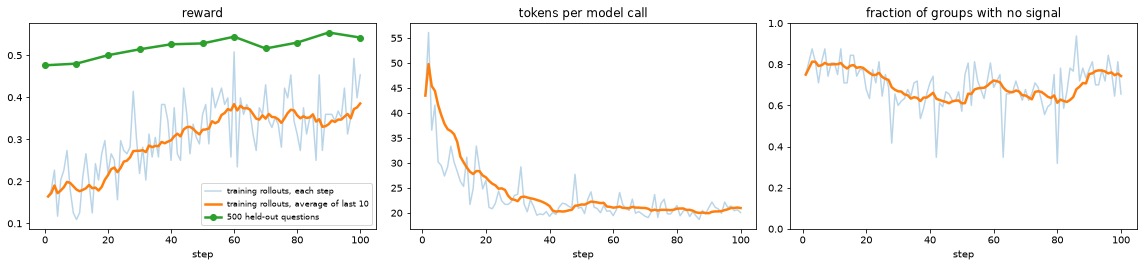

In [ ]:
import matplotlib.pyplot as plt

long_run = [json.loads(line) for line in open(REPO / "tutorial/series/results/calc_x_long_run.jsonl")]
validation = pd.Series({record["step"]: record["data"]["val/reward"] for record in long_run if "val/reward" in record["data"]})
training = pd.DataFrame([{"step": record["step"], **record["data"]} for record in long_run if "training/reward" in record["data"]]).set_index("step")

fig, (reward_axis, length_axis, groups_axis) = plt.subplots(1, 3, figsize=(16, 3.8))

reward_axis.plot(training["training/reward"], alpha=0.3, label="training rollouts, each step")
reward_axis.plot(training["training/reward"].rolling(10, min_periods=1).mean(), linewidth=2.5, label="training rollouts, average of last 10")
reward_axis.plot(validation, marker="o", linewidth=2.5, label="500 held-out questions")
reward_axis.set_title("reward")
reward_axis.set_xlabel("step")
reward_axis.legend(fontsize=8)

length_axis.plot(training["response_length/training/avg_by_turn"], alpha=0.3)
length_axis.plot(training["response_length/training/avg_by_turn"].rolling(10, min_periods=1).mean(), linewidth=2.5)
length_axis.set_title("tokens per model call")
length_axis.set_xlabel("step")

no_signal = training["training/n_zero_adv_groups"] / training["training/n_groups"]
groups_axis.plot(no_signal, alpha=0.3)
groups_axis.plot(no_signal.rolling(10, min_periods=1).mean(), linewidth=2.5)
groups_axis.set_title("fraction of groups with no signal")
groups_axis.set_xlabel("step")
groups_axis.set_ylim(0, 1)

plt.tight_layout()
plt.show()

Firstly, **the agent improves**. The reward on the held-out questions rises from 0.476 to 0.542 over 100 steps, peaking at 0.554. Validation samples one answer per question, at temperature 0.7 (Agent Lightning's default for validation), so each measurement is noisy: with 500 questions, about ±2 percentage points, which is why it dips at step 70. The trend over the whole run, however, is clear. The training reward, sampled at temperature 1, roughly doubles, from about 0.18 to about 0.39 (averaged over 10 steps).

Secondly, **the model's calls get much shorter**, from about 45 tokens to about 20. The agent still makes about two model calls per rollout, so it hasn't stopped using its tool. What disappears is the text around the calls, such as the preamble in §3's rollout, after which the model wrote its tool call without the tags that the parser looks for.

Finally, **most groups still have no signal**: between about 60% and 80% of them, every step, as all four rollouts of most questions get the same reward. So, most of the rollouts in this run were spent on questions that the model always or never answers correctly, and taught it nothing. This is the main cost of training on a fixed dataset with small groups, and production setups address it by filtering the questions, sampling more rollouts per question, or both.

It's a modest gain for 53 minutes, and the full Calc-X recipe runs 512 steps. However, it is a real, unmodified agent, improving through every piece that we have built in this series.

#### Asynchronous rollouts on one GPU

In the previous article (§3), we saw why production setups often train asynchronously: so that generation doesn't wait for the update, or for the slowest rollout in the batch. Agent Lightning has an asynchronous mode of its own, turned on with `--async` in the Calc-X example, which works a little differently from the one-step-off scheme we drew there:

1. **Queue more than a step needs.** Each step queues twice as many questions as `train_batch_size`, so there are always more rollouts running than the step will use.
2. **Train on the first groups to finish.** As soon as `train_batch_size` groups have finished, the step goes ahead and trains on them, without waiting for the slow ones.
3. **Pause during the update.** The Gateway stops accepting new model calls, waits for the calls already in flight to finish (it *drains*), and vLLM is put to sleep while the training model is updated, as in the synchronous runs.
4. **Carry the rest over.** Rollouts that didn't finish in time aren't thrown away: they continue after the update, and join a later step. Their earlier model calls were made with the old weights, so they are slightly stale.

So, does it work on our single GPU? I ran it for 20 steps, with the same recipe and questions as the long run, again with `tools/calc_x_long_run.py` (adding `--async`), and compared it with the first 20 steps of the synchronous run:

In [ ]:
def read_steps(path: Path, num_steps: int) -> pd.DataFrame:
    # One row per training step, skipping the validation-only records, for the first num_steps steps
    records = [json.loads(line) for line in open(path)]
    steps = pd.DataFrame([{"step": record["step"], **record["data"]} for record in records
                          if "training/reward" in record["data"]]).set_index("step")
    return steps.loc[1:num_steps]


synchronous = read_steps(REPO / "tutorial/series/results/calc_x_long_run.jsonl", 20)
asynchronous = read_steps(REPO / "tutorial/series/results/calc_x_async_run.jsonl", 20)

metrics = {
    "timing_s/step": "step time (s)",
    "timing_s/gen": "rollouts (s)",
    "timing_s/update_actor": "update (s)",
    "timing/rollout_total_s/mean": "a rollout, queued to finished (s)",
    "timing/rollout_run_duration_s/mean": "a rollout, running (s)",
    "training/reward": "training reward",
    "rollout_corr/kl": "rollout_corr/kl",
    "training/async/n_new_carry_over_rollouts": "rollouts carried over",
    "training/async/new_carry_over_age_max_steps": "oldest carried-over rollout (steps)",
    "training/async/proxy_inflight_at_pause": "model calls in flight at the pause",
    "training/async/proxy_drain_seconds": "time to drain them (s)",
}
# The mean of each metric over the 20 steps; the async-only metrics are blank for the synchronous run
comparison = pd.DataFrame({
    "synchronous": synchronous.reindex(columns=list(metrics)).mean(),
    "asynchronous": asynchronous.reindex(columns=list(metrics)).mean(),
}).rename(index=metrics)
comparison.round(3).fillna("")

,synchronous,asynchronous
step time (s),24.731,24.577
rollouts (s),13.711,12.341
update (s),6.713,6.721
"a rollout, queued to finished (s)",7.429,22.946
"a rollout, running (s)",3.245,7.797
training reward,0.198,0.182
rollout_corr/kl,0.001,0.001
rollouts carried over,,128.000
oldest carried-over rollout (steps),,0.250
model calls in flight at the pause,,8.400


It works: 20 steps, with no errors, and the training model and vLLM agree as closely as before (`rollout_corr/kl` is unchanged). The staleness is small, as the oldest carried-over rollout is nearly always from the current step, and only occasionally from the one before. However, **it is no faster**: the step time is the same, and the rollouts take only about 10% less time. There are two reasons for this:

* **Calc-X rollouts are short and similar in length.** A rollout runs for a few seconds, so there are hardly any slow rollouts for the step to stop waiting for. Asynchronous training pays off when rollouts are long and uneven, such as agents that browse, run code, or make dozens of calls.
* **On one GPU, generation and the update still take turns.** The Gateway pauses and vLLM sleeps during every update, so nothing overlaps. The bigger gain needs separate GPUs for each role (the *disaggregated* layout of the previous article's §4), so that generation can carry on during the update.

It also has a cost: with twice as many rollouts queued, each one waits about three times as long from being queued to finishing, and even runs for longer, as twice as many agents share vLLM at once. So, on a single GPU, with short rollouts like these, the synchronous mode is the simpler choice.

The synchronous run also shows where a rollout's time goes: about 3 s running, and about 4 s waiting in the queue, mostly for the Controller to start the agent's process and for the agent to start its MCP calculator. With agents this quick, starting them costs more than waiting for the slow ones.

In [33]:
for name in ["agl_controller", "agl_gateway"]:
    stop_service(name)
shutil.rmtree(SHM, ignore_errors=True)  # the weights we wrote for vLLM
print("remaining services:", [name for name, proc in SERVICES.items() if proc.poll() is None])
print(f"GPU free: {gpu_free_gib():.0f} GiB")

stopped agl_controller


stopped agl_gateway


remaining services: []


GPU free: 92 GiB


## What we built

Over this article, we have extended our training loop from single responses to agents, and then to an existing agent program:

| Problem | Solution | Ours | Production (verl and Agent Lightning) |
|---|---|---|---|
| an agent's sample mixes the model's tokens with the tools' | one sequence, with `response_mask = 0` on the tools' tokens | `run_episodes` | verl's `ToolAgentLoop` |
| an existing agent speaks HTTP, owns its control flow, and its logs can't be turned back into tokens reliably | record the exact tokens at the HTTP boundary, under a URL per rollout | our gateway, `launch_agent` | Agent Lightning's Gateway and Controller |
| a rollout makes several model calls | one advantage per rollout, copied onto its rows | `gateway_batch` | `RolloutAdapter`, `compute_rollout_level_advantage` |
| calls that extend each other are trained separately | merge them into one row when prefix continuity holds | | the `trajectory` level |
| rollouts with more tokens count for more in the loss | give every rollout the same total weight | | `per_rollout_mean` |
| where does the reward come from? | the agent's own check, or a judge with its own endpoint | | the agent posts it as an event |
| our training loop | everything above, wired together and configured from one tree | | `AgentLightningRayPPOTrainer`, on verl |

**Which to use when:**

* For a **single-turn** task, or an agent that we're happy to write as a verl agent loop, with verl tools, **verl alone** is the simpler choice.
* For an **existing agent**, with its own framework, tools, processes or containers, or code we don't control, **verl with Agent Lightning** lets us train it as it is: the agent only changes its base URL.

**Wrapping up the series.** Over three articles, we have built every part of a production RL setup for LLMs ourselves: the GRPO algorithm, in a training loop of plain PyTorch; an inference engine with weight sync, separate processes and worker groups; and, in this article, multi-turn rollouts and the recording of an existing agent's model calls. After each piece, we checked it against the version in verl or Agent Lightning, so that, when one of these frameworks does something unexpected, we know which piece is responsible, and why it exists.